# Le marché de l'emploi romand en 5 graphiques

Les offres **actives** de la base (`data/jobs.duckdb`, vue gold `jobs_view`), collectées
directement chez les employeurs de Suisse romande (GE, VD, FR, NE, VS, JU et Jura bernois ;
l'arc lémanique seul jusqu'au 4.11.2026). Relancer de haut en bas après
une collecte :

```bash
uv run --group notebook jupyter nbconvert --to notebook --execute --inplace notebooks/marche-emploi.ipynb
```

Les images sont aussi écrites dans `docs/img/` pour le README.

In [1]:
from datetime import date
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(str(ROOT / "data" / "jobs.duckdb"), read_only=True)

# Palette de référence (thème clair) : une seule série par graphique, donc une seule teinte ;
# le texte reste dans les encres de texte, jamais dans la couleur de la série
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
SERIES, MUTED = "#2a78d6", "#a3a29d"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK,
    "text.color": INK, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": True, "axes.grid.axis": "x", "grid.color": GRID,
    "axes.axisbelow": True, "figure.dpi": 110,
})


def sql(query):
    return con.execute(query).fetchall()


def barh(rows, title, path, colors=None, fmt="{:d}"):
    """Barres horizontales triées, la plus grande en haut, valeur au bout de chaque barre."""
    labels, values = zip(*rows)
    height = 0.6 + 0.32 * len(rows)
    fig, ax = plt.subplots(figsize=(8, height))
    bars = ax.barh(labels[::-1], values[::-1], color=(colors or [SERIES] * len(rows))[::-1],
                   height=0.7)
    for bar, value in zip(bars, values[::-1]):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, " " + fmt.format(value),
                va="center", color=INK_2, fontsize=9)
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", pad=12)
    ax.tick_params(axis="y", length=0)
    ax.margins(x=0.08)
    fig.tight_layout()
    fig.savefig(IMG / path, bbox_inches="tight")
    plt.show()


total, = sql("SELECT count(*) FROM jobs_view WHERE active")[0]
cantons = dict(sql("SELECT canton, count(*) FROM jobs_view WHERE active GROUP BY 1"))
employers, = sql("SELECT count(DISTINCT company) FROM jobs_view WHERE active")[0]
by_canton = ", ".join(f"{c} {n}" for c, n in sorted(cantons.items(), key=lambda x: -x[1]) if c)
print(f"{total} offres actives, {employers} employeurs : {by_canton} "
      f"(au {date.today():%d.%m.%Y})")

1650 offres actives, 49 employeurs : GE 633, VD 406, FR 228, VS 206, NE 105, BE 51, JU 21 (au 04.11.2026)


## 1. Les 20 employeurs qui recrutent le plus

À lire avec prudence : c'est le nombre d'offres **publiées**, pas d'embauches. Coop publie
une annonce par magasin et par poste (« Apprentissage… » à Lausanne, Bussigny, Carouge…) ;
une banque publie une annonce pour un poste qui en couvre parfois plusieurs.

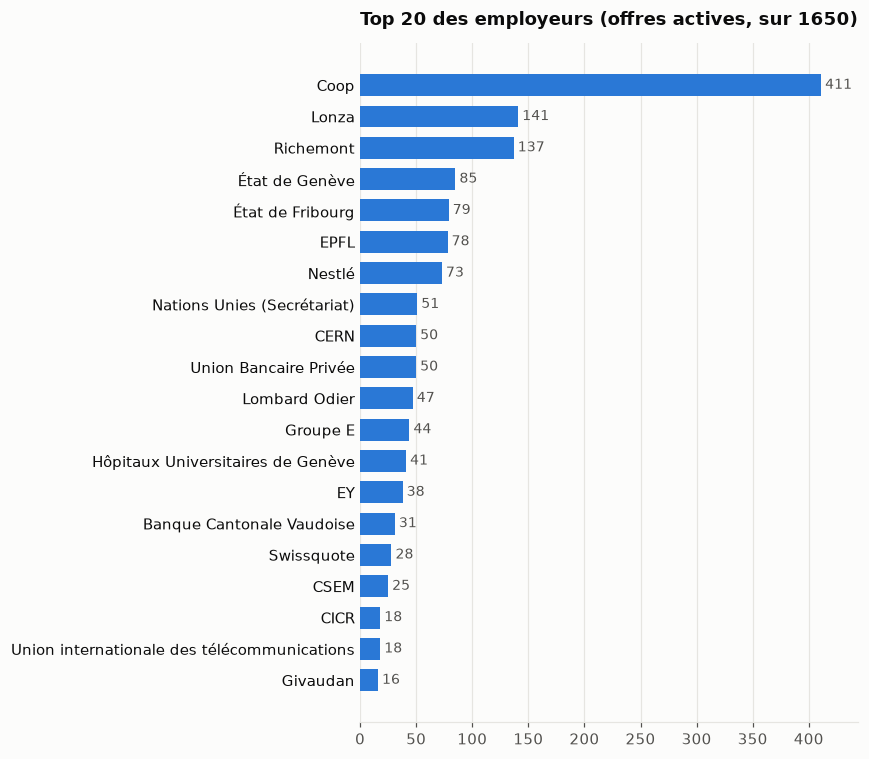

In [2]:
rows = sql("""SELECT company, count(*) n FROM jobs_view WHERE active
              GROUP BY 1 ORDER BY n DESC, company LIMIT 20""")
barh(rows, f"Top 20 des employeurs (offres actives, sur {total})", "top-employeurs.png")

## 2. La langue des offres

Détectée sur la description ; « autre » = ni français ni anglais : de l'**allemand**
depuis l'élargissement à la Romandie (Lonza à Viège, Coop dans le Haut-Valais, l'État de
Fribourg bilingue), ou un texte trop court pour trancher (une annonce Coop sans description).

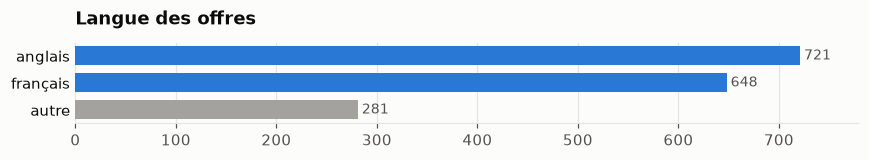

anglais        721  44%
français       648  39%
autre          281  17%


In [3]:
names = {"en": "anglais", "fr": "français", "other": "autre"}
rows = [(names.get(lang, lang), n) for lang, n in
        sql("SELECT language, count(*) n FROM jobs_view WHERE active GROUP BY 1 ORDER BY n DESC")]
barh(rows, "Langue des offres", "langues.png",
     colors=[MUTED if label == "autre" else SERIES for label, _ in rows],
     fmt="{:d}")
for label, n in rows:
    print(f"{label:<13} {n:>4}  {n / total:.0%}")

## 3. Les familles de métiers

Classement par mots-clés du titre (`families.py`). « Autre » (en gris) = aucun mot-clé
reconnu : c'est la limite des règles, que l'extraction par LLM (M5) devra combler.

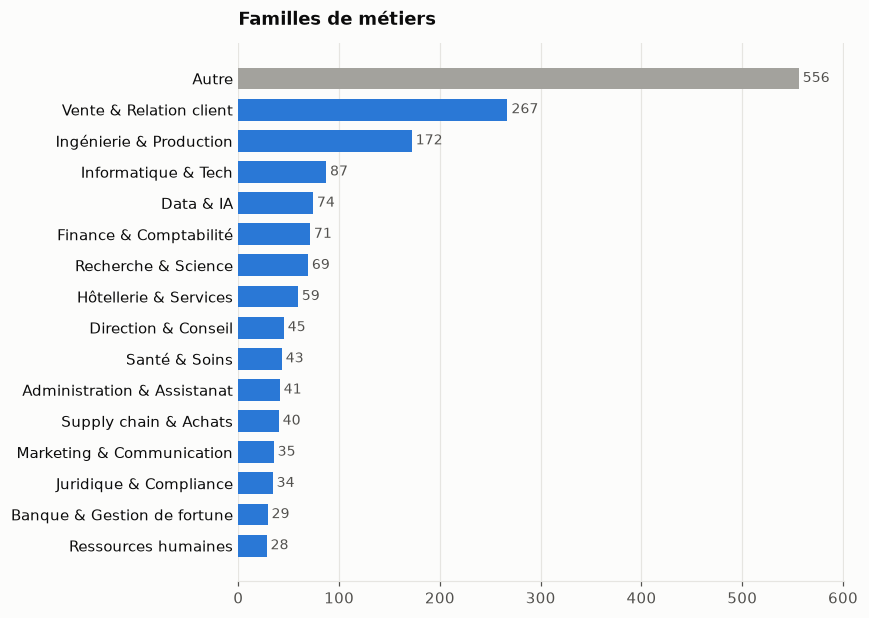

« Autre » : 556 offres (34%), dont 94 chez Coop


In [4]:
rows = sql("""SELECT family, count(*) n FROM jobs_view WHERE active
              GROUP BY 1 ORDER BY n DESC""")
barh(rows, "Familles de métiers", "familles.png",
     colors=[MUTED if family == "Autre" else SERIES for family, _ in rows])
autre = dict(rows).get("Autre", 0)
coop, = sql("""SELECT count(*) FROM jobs_view
             WHERE active AND family = 'Autre' AND company = 'Coop'""")[0]
print(f"« Autre » : {autre} offres ({autre / total:.0%}), dont {coop} chez Coop")

## 4. Les secteurs

Le secteur est celui de l'**employeur** (`data/companies.csv`), pas du poste : un
informaticien de l'UBP compte dans « Banque ».

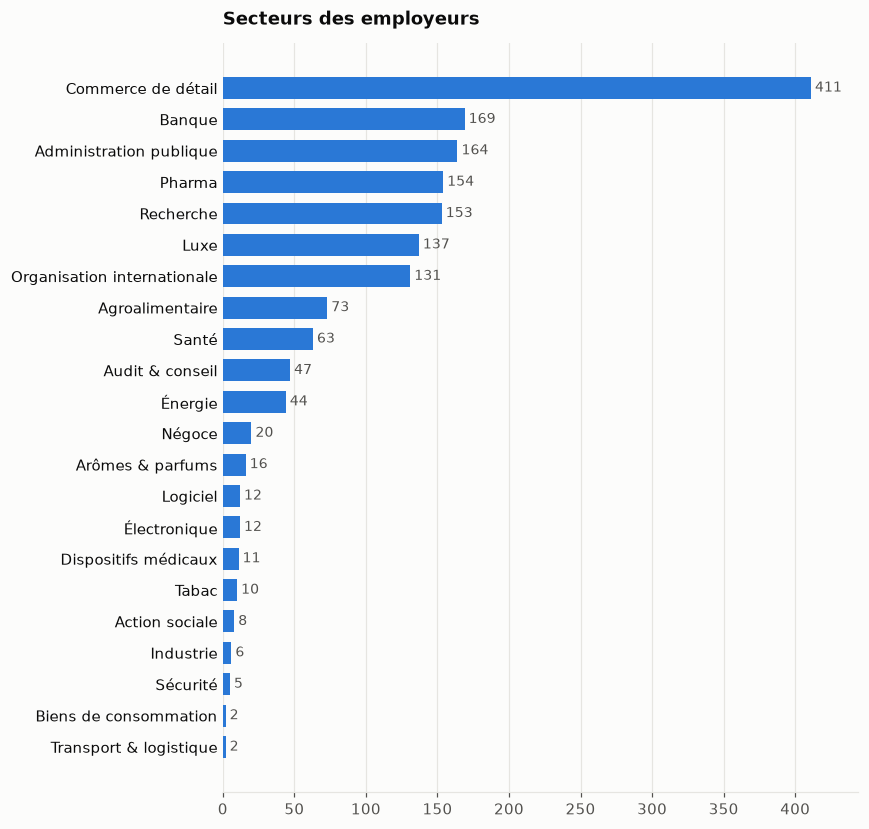

In [5]:
rows = sql("""SELECT sector, count(*) n FROM jobs_view WHERE active
              GROUP BY 1 ORDER BY n DESC""")
barh(rows, "Secteurs des employeurs", "secteurs.png")

## 5. L'âge des offres

Jours écoulés depuis la date de publication. La plupart des offres ont moins de deux
mois ; la traîne à droite, ce sont des annonces « permanentes » (viviers, candidatures
spontanées) republiées depuis des mois, voire des années. Pour la recommandation, c'est
l'argument du score de fraîcheur (M6).

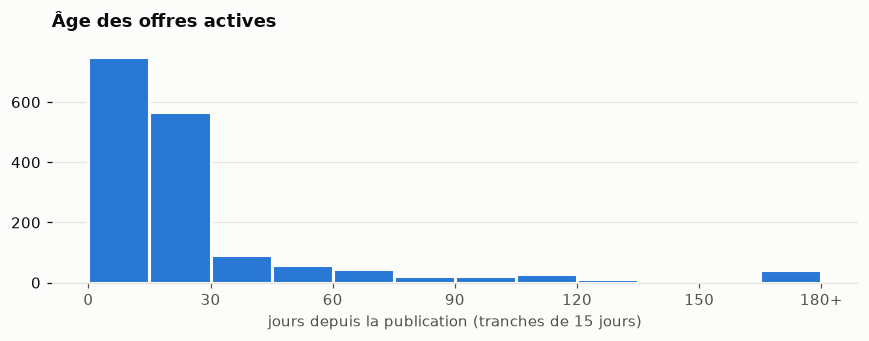

1650 offres datées ; âge médian 16 jours ; 81% ont moins d'un mois, 36 plus de 180 jours


In [6]:
ages = [(date.today() - d).days for (d,) in
        sql("SELECT posted_at FROM jobs_view WHERE active AND posted_at IS NOT NULL")]
CAP = 180
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist([min(a, CAP) for a in ages], bins=range(0, CAP + 15, 15), color=SERIES,
        edgecolor=SURFACE, linewidth=2)
ax.set_xticks(range(0, CAP + 1, 30), [*map(str, range(0, CAP, 30)), f"{CAP}+"])
ax.set_xlabel("jours depuis la publication (tranches de 15 jours)")
ax.set_title("Âge des offres actives", loc="left", fontsize=12, fontweight="bold", pad=12)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", visible=True)
fig.tight_layout()
fig.savefig(IMG / "age-offres.png", bbox_inches="tight")
plt.show()
ages.sort()
median = ages[len(ages) // 2]
print(f"{len(ages)} offres datées ; âge médian {median} jours ; "
      f"{sum(a <= 30 for a in ages) / len(ages):.0%} ont moins d'un mois, "
      f"{sum(a > CAP for a in ages)} plus de {CAP} jours")

## Bonus : les cantons

Le canton du **lieu de l'offre** (pas celui du siège de l'employeur). « BE » = le Jura bernois
et Bienne seulement. Le périmètre a été élargi à toute la Suisse romande le 4.11.2026 :
l'arc lémanique domine encore, parce que la liste d'employeurs y a été construite d'abord.

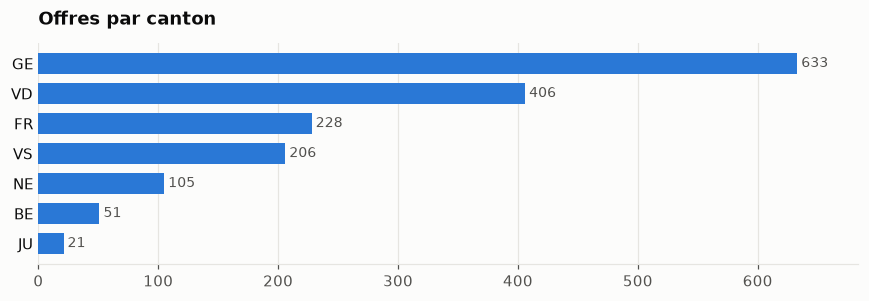

sans canton : 0


In [7]:
ORDER = ["GE", "VD", "FR", "NE", "VS", "JU", "BE"]
rows = sorted(((c, cantons.get(c, 0)) for c in ORDER), key=lambda row: -row[1])
barh(rows, "Offres par canton", "cantons.png")
unknown = cantons.get(None, 0)
print(f"sans canton : {unknown}")

## Bonus : la séniorité

Deux sources, dans cet ordre (`families.py`) : un mot-clé du titre (« Senior », « Head of »,
« Stagiaire », « Postdoc »…), sinon les années d'expérience demandées dans la description
(« 3-5 years of experience » → milieu de la fourchette : ≤ 2 ans Junior, ≤ 5 Confirmé·e,
au-delà Senior / Lead). « Non précisé » (en gris) = ni l'un ni l'autre : surtout des annonces
Coop sans description, et des titres neutres (« Comptable », « Data Engineer »). Les barres
suivent l'ordre de la carrière, pas le nombre d'offres.

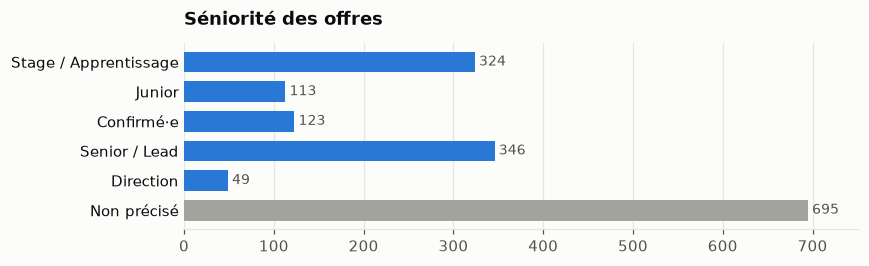

« Non précisé » : 695 offres (42%), dont 270 chez Coop


In [8]:
LEVELS = ["Stage / Apprentissage", "Junior", "Confirmé·e", "Senior / Lead", "Direction",
          "Non précisé"]
counts = dict(sql("SELECT seniority, count(*) FROM jobs_view WHERE active GROUP BY 1"))
rows = [(level, counts.get(level, 0)) for level in LEVELS]
barh(rows, "Séniorité des offres", "seniorite.png",
     colors=[MUTED if level == "Non précisé" else SERIES for level in LEVELS])
coop, = sql("""SELECT count(*) FROM jobs_view
             WHERE active AND seniority = 'Non précisé' AND company = 'Coop'""")[0]
unknown = counts.get("Non précisé", 0)
print(f"« Non précisé » : {unknown} offres ({unknown / total:.0%}), dont {coop} chez Coop")